<a href="https://colab.research.google.com/github/hilduAgl/brain-age-eeg/blob/main/notebooks/baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature-Based Baseline

This notebook builds a simple feature-based baseline for predicting a child's age from EEG. Each recording is reduced to a small set of hand-crafted features from a single channel, and a linear regression model maps those features to age. The result is the reference point the CNN has to beat.

## Goals

- Compute a constant-age reference (always predicting the training mean/median) on the validation set
- Load channel 14 (C3-P3) for each subject
- Implement Hjorth parameters (activity, mobility, complexity) and test them on synthetic signals
- Implement band-power features (delta, theta, alpha, beta) consistent with the starter implementation
- Build and save feature tables for the training and validation subjects
- Explore how each feature relates to age
- Train a standardized linear regression model on the training set only
- Evaluate on the validation set using MAE and RMSE, and compare with the constant-age reference

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "/content/drive/MyDrive/BrainAge/data"
EEG_DIR = os.path.join(DATA_DIR, "pre_processed")
METADATA_PATH = os.path.join(DATA_DIR, "anon_codex_age_sex.csv")

TRAIN_PATH = os.path.join(DATA_DIR, "segments_h1k_train.pt")
VAL_PATH = os.path.join(DATA_DIR, "segments_h1k_val.pt")
TEST_PATH = os.path.join(DATA_DIR, "segments_h1k_test.pt")

RESAMPLING_RATE = 64   # Hz, as in eda.ipynb
CHANNEL = 14           # C3-P3, chosen in eda.ipynb

In [3]:
print(os.listdir(DATA_DIR))
print("EEG files:", len(os.listdir(EEG_DIR)))

['anon_codex_age_sex.csv', 'segments_h1k_val.pt', 'segments_h1k_train.pt', 'segments_h1k_test.pt', 'pre_processed']
EEG files: 1034


In [4]:
train_data = torch.load(TRAIN_PATH)
val_data = torch.load(VAL_PATH)

print("Train:", len(train_data))
print("Val:", len(val_data))
print(train_data[0])

Train: 825
Val: 103
(0, 901, 0, 5.284383562, '8128DH.edf')


## 1. Constant-age reference: predicting age with no EEG data

In [5]:
from sklearn.metrics import mean_absolute_error

# Ages from each split
y_train = np.array([train_data[i][3] for i in range(len(train_data))])
y_val = np.array([val_data[i][3] for i in range(len(val_data))])

# One constant guess
mean_guess = np.mean(y_train)
median_guess = np.median(y_train)

# Predict that guess for every validation child
pred_mean = np.full(len(y_val), mean_guess)
pred_median = np.full(len(y_val), median_guess)

print("Mean guess:  ", mean_guess, "-> val MAE:", mean_absolute_error(y_val, pred_mean))
print("Median guess:", median_guess, "-> val MAE:", mean_absolute_error(y_val, pred_median))

Mean guess:   4.588638249135758 -> val MAE: 3.4722103478766466
Median guess: 2.975479452 -> val MAE: 2.9775349512330096



By calculating the mean and median ages of the training data to predict the ages in the validation data we get an MAE of 2.98 years when using median age. That means our challenge is to make a baseline model that is more accurate than an MAE of 2.98 years by utilising data found in the EEG.

## 2. Inspecting a single recording (channel 14, C3-P3)

Shape of full recording: torch.Size([20, 57664])
Samples in channel 14: 57664
Duration (s): 901.0


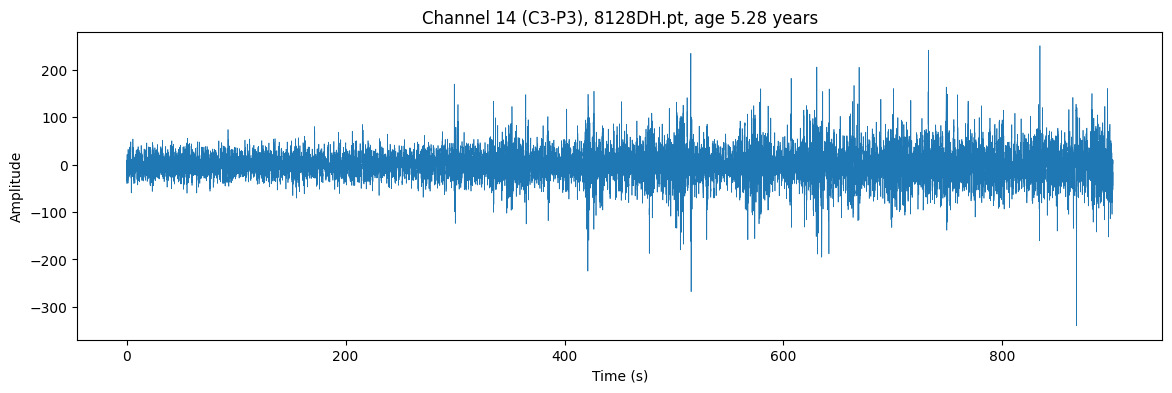

In [6]:
filename = train_data[0][4].replace(".edf",".pt")
path = os.path.join(EEG_DIR, filename)

eeg = torch.load(path).float()
signal = eeg[CHANNEL].numpy()

print("Shape of full recording:", eeg.shape)
print("Samples in channel 14:", len(signal))
print("Duration (s):", len(signal) / RESAMPLING_RATE)

time = np.arange(len(signal)) / RESAMPLING_RATE

plt.figure(figsize=(14, 4))
plt.plot(time, signal, linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"Channel 14 (C3-P3), {filename}, age {train_data[0][3]:.2f} years")
plt.show()

looking at the eeg channel in this recording we can see a change in amplitude around 300s, my best guess as to what causes the change is that's the point in time when the child falls asleep as the rest of the channel has a larger amplitude than the first roughly 300s. We found in the project starter notebook that approximately the first 300s are the pre-N2 onset region (before the children fall into N2 sleep). This area might be a good place to start with a baseline model.

## 4. Feature functions: Hjorth parameters

In [7]:
def mobility(x):
    return np.sqrt(np.var(np.diff(x)) / (np.var(x) + 1e-6))

def hjorth(x):
    # x: 1D numpy array, one channel of EEG
    activity = np.var(x)
    mob = mobility(x)
    complexity = mobility(np.diff(x)) / (mob + 1e-6)
    return activity, mob, complexity

In [9]:
t = np.arange(0, 10, 1/RESAMPLING_RATE)   # 10 seconds of time at 64 Hz
slow = np.sin(2 * np.pi * 2 * t)          # 2 Hz sine
fast = np.sin(2 * np.pi * 10 * t)         # 10 Hz sine
big  = 5 * np.sin(2 * np.pi * 2 * t)      # 2 Hz sine, 5x bigger

for name, sig in [("slow", slow), ("fast", fast), ("big", big)]:
    a, m, c = hjorth(sig)
    print(f"{name:5s}  activity={a:.3f}  mobility={m:.3f}  complexity={c:.3f}")

slow   activity=0.500  mobility=0.196  complexity=1.003
fast   activity=0.500  mobility=0.942  complexity=1.001
big    activity=12.500  mobility=0.196  complexity=1.003


We have set up the hjorth feature calculations and to test if they are correct we used some code generated by claude to see if what should happen actually happens. The expected outcome is that mobility will be highest on the fast wave, activity will be highest on the big wave. The results matched the predicted outcome showing us that our hjorth features are set up correctly.